## SECTION  A OF THE QUESTION:POPULATION MORTALITY
#### **.Population pyramid and interpretation
#### **.calculation of rations
#### **.Balancing equation and calculation of other ratios
#### **.Abridged life table

**DISTRICT CHOSEN BY THE GROUP (D001 AND D003)**

In [154]:
#importing the necessary libraries that are required for the analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [155]:
#IMPORTING THE DATASET INTO THE NOTEBOOK
df = pd.read_csv("../data/age_sex.csv")

#### **SINCE THE DATASET IS FREE FROM MISSING VALUES THERE IS NO NEED TO DO CLEANING WE CONTINUE WITH THE PROCESS OF CHOOSING THE DISTRICTS THAT WE NEE (D001 AND D003)**

In [156]:
#SELECTING THE 2 REQUIRED DISTRICTS
df = df[df["district_id"].isin(["D01", "D03"])].copy()

In [157]:
#OVERLOOKING THE SELECTED DISTRICT DATASET 
df.tail(4)

,district_id,age_start,sex,population_2025,baseline_deaths_2025,arrivals_2025,departures_2025,births_to_women_2025,survival_5yr
104,D03,80,F,2007,142,38,35,0,0.701273
105,D03,80,M,1840,134,26,38,0,0.695364
106,D03,85,F,1633,245,34,26,0,0.471765
107,D03,85,M,1495,259,24,26,0,0.420943


In [158]:
#CREATE THE FIVE YEAR INTERVALS FOR THE DATASETS SO THAT THE PLOTTING OF THE PYRAMIDS WILL BE A SUCCESS
df["age_group"] = df["age_start"].apply(
    lambda x: "85+" if x == 85 else f"{int(x)}-{int(x+4)}")

In [159]:
df['age_group']

0        0-4
1        0-4
2        5-9
3        5-9
4      10-14
       ...  
103    75-79
104    80-84
105    80-84
106      85+
107      85+
Name: age_group, Length: 72, dtype: str

In [160]:
#MAKING THE MALE POPULATION NEGATIVE SO THAT ITN CAN BE PLOTTED ON THE PYRAMID
df["population_plot"] = np.where(
    df["sex"] == "M",
    -df["population_2025"],
    df["population_2025"])

In [161]:
#PREPARING THE DATASET FOR  PLOTTING
pyramid_data = df.pivot_table(
    index=["age_start", "age_group"],
    columns=["district_id", "sex"],
    values="population_plot",
    aggfunc="sum"
).reset_index()

pyramid_data = pyramid_data.sort_values("age_start")

In [162]:
#THE ASSIGNMENT REQUIRES A COMMON SCALE TO BE USED IN THE DATASET SO THIS SECTION SERVES AS A CALCULATION OF A COMMON SCALE
max_population = max(
    df["population_2025"].max(),
    df.groupby(["district_id", "age_group"])["population_2025"].sum().max()
)

limit = np.ceil(max_population / 1000) * 1000


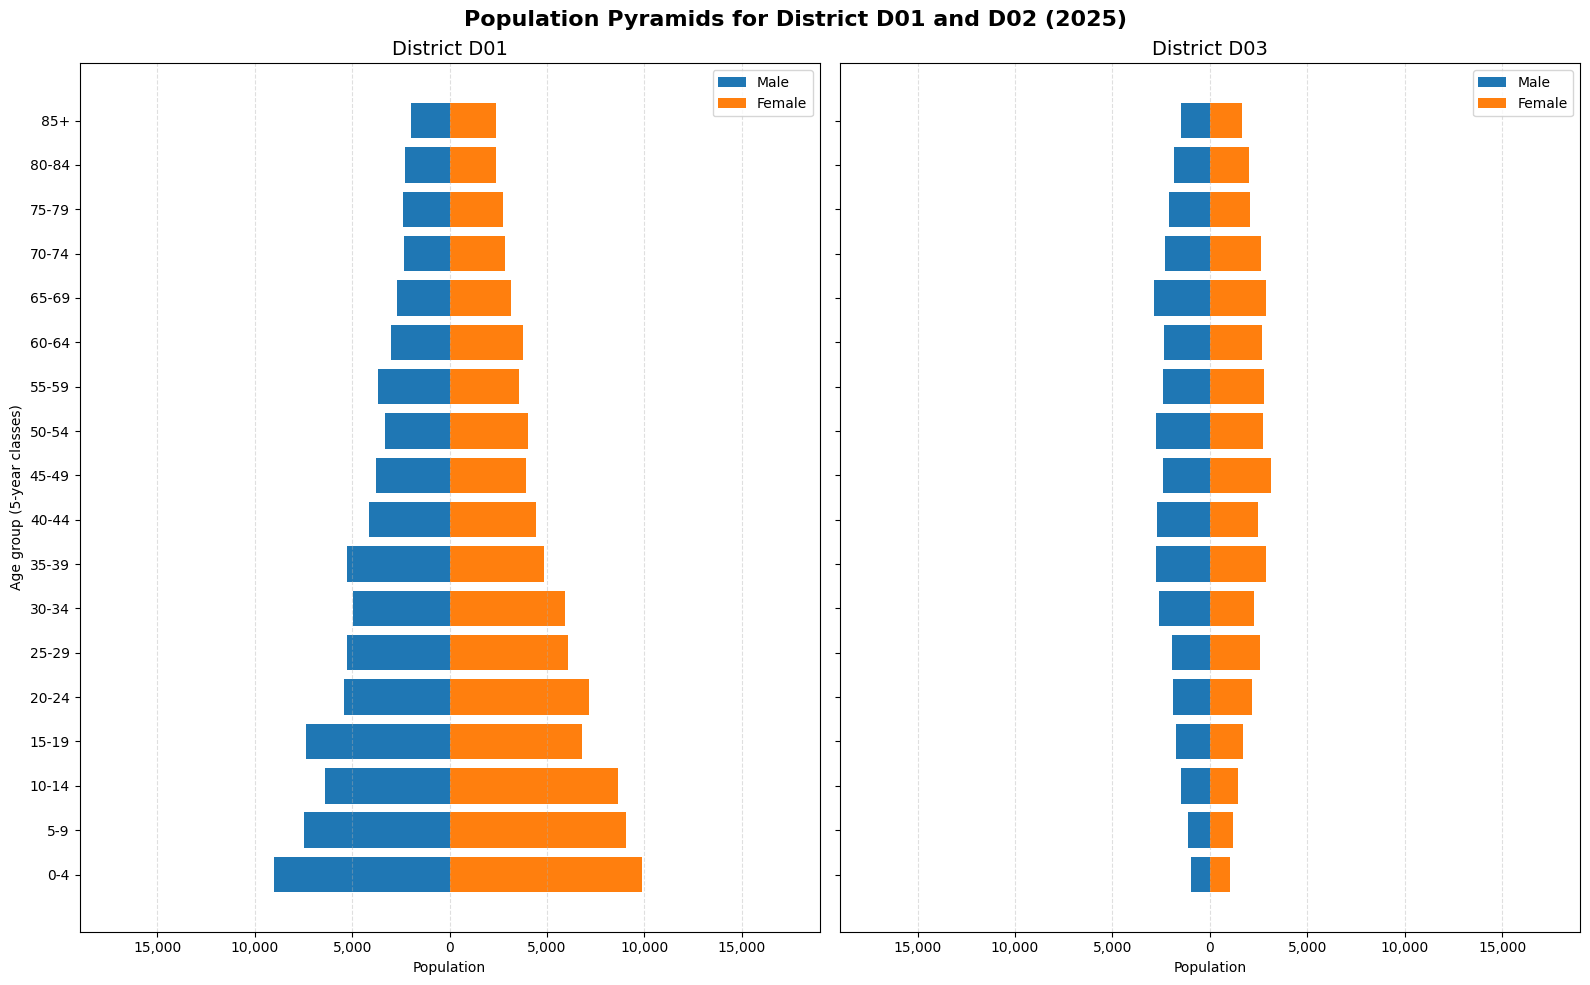

In [163]:
#WE NEED TO CREATE THE TWO PYRAMIDS SIDE BY SIDE 
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 10),
    sharey=True
)

districts = ["D01", "D03"]

for ax, district in zip(axes, districts):

    district_data = df[df["district_id"] == district]

    # Aggregate population by age and sex
    plot_data = district_data.pivot_table(
        index=["age_start", "age_group"],
        columns="sex",
        values="population_plot",
        aggfunc="sum"
    ).reset_index().sort_values("age_start")

    # Draw male and female bars
    ax.barh(
        plot_data["age_group"],
        plot_data["M"],
        label="Male"
    )

    ax.barh(
        plot_data["age_group"],
        plot_data["F"],
        label="Female"
    )

    # Apply identical scale
    ax.set_xlim(-limit, limit)

    # Format axis labels as positive numbers
    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f"{abs(x):,.0f}")
    )

    ax.set_title(f"District {district}", fontsize=14)
    ax.set_xlabel("Population")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.legend()

#Add common title and labels
axes[0].set_ylabel("Age group (5-year classes)")

fig.suptitle(
    "Population Pyramids for District D01 and D02 (2025)",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout()
plt.show()


### **Coment**
The population pyramids reveal contrasting demographic structures between District D01 and the second district. District D01 exhibits an expansive population structure, characterised by a broad base representing relatively large populations in the younger age groups, particularly those aged 0–14 years. The population generally decreases with increasing age, resulting in a relatively narrow upper section. This structure is consistent with a youthful population and may reflect relatively high fertility levels in previous years. Consequently, the district may experience increased demand for educational facilities, maternal healthcare and other child-related services.

In contrast, the second district exhibits a constrictive population structure, with a relatively narrow base and greater concentration in the middle-age groups, particularly between 30 and 54 years. This suggests a relatively smaller younger population and a population structure that may be experiencing ageing. The relatively greater representation of older age groups compared with children could increase future demand for healthcare and elderly support services.

The differences between the two districts demonstrate the importance of considering local population structures when allocating resources and planning public services. While District D01 may require greater investment in education and youth-oriented services, the second district may require increased attention to healthcare and services for an ageing population.

However, population pyramids describe population composition at a particular point in time and do not independently establish the causes of demographic differences. Fertility, mortality and migration data are therefore necessary to support these interpretations.

## **MOVING TO THE NEXT SECTION OF CALCULATING  THE DEMOGRAPHIC INDICATORS OF POPULATION IN D01 AND 003**

##### *SEX RARIO*
##### *YOUTH DEPENDENCY RATIO*
##### *OLD-AGE DEPENDENCY RATIO*

In [164]:
#XLEANING THE DATASET FOR CALCULATING THE RATIOS
# Clean district and sex identifiers
df = pd.read_csv("../data/age_sex.csv") #reloading the data so that previous changes cant affect this part

df["district_id"] = df["district_id"].str.strip().str.upper()
df["sex"] = df["sex"].str.strip().str.upper()

# Select District D01 and D03
df = df[df["district_id"].isin(["D01", "D03"])].copy()

# Check selected districts
print(df.groupby("district_id").size())


district_id
D01    36
D03    36
dtype: int64


In [165]:
# Classify population into demographic age groups

df["demographic_group"] = np.select(
    [
        df["age_start"] <= 10,
        df["age_start"].between(15, 60),
        df["age_start"] >= 65
    ],
    [
        "Youth",
        "Working Age",
        "Elderly"
    ],
    default="Check"
)

display(
    df[["age_start", "demographic_group"]]
    .drop_duplicates()
    .sort_values("age_start")
)

,age_start,demographic_group
0,0,Youth
2,5,Youth
4,10,Youth
6,15,Working Age
8,20,Working Age
10,25,Working Age
12,30,Working Age
14,35,Working Age
16,40,Working Age
18,45,Working Age


In [166]:
results = []

for district in ["D01", "D03"]:

    data = df[df["district_id"] == district]

    # Total male and female populations
    male = data.loc[data["sex"] == "M", "population_2025"].sum()
    female = data.loc[data["sex"] == "F", "population_2025"].sum()

    # Population by age category
    youth = data.loc[
        data["demographic_group"] == "Youth",
        "population_2025"
    ].sum()

    working_age = data.loc[
        data["demographic_group"] == "Working Age",
        "population_2025"
    ].sum()

    elderly = data.loc[
        data["demographic_group"] == "Elderly",
        "population_2025"
    ].sum()

    # Calculate demographic indicators
    sex_ratio = (male / female) * 100

    youth_dependency = (youth / working_age) * 100

    old_age_dependency = (elderly / working_age) * 100

    results.append({
        "District": district,
        "Male Population": male,
        "Female Population": female,
        "Youth Population": youth,
        "Working Age Population": working_age,
        "Elderly Population": elderly,
        "Sex Ratio": sex_ratio,
        "Youth Dependency Ratio": youth_dependency,
        "Old-Age Dependency Ratio": old_age_dependency
    })

# Create results table
indicators = pd.DataFrame(results)

display(indicators.round(2))

,District,Male Population,Female Population,Youth Population,Working Age Population,Elderly Population,Sex Ratio,Youth Dependency Ratio,Old-Age Dependency Ratio
0,D01,80875,91570,50483,96727,25235,88.32,52.19,26.09
1,D03,37719,40188,7232,48883,21792,93.86,14.79,44.58


INTERPRETATION OF THE RESULTS

From the above results we can see that  sex ratio for district 1 and 3 are different with distict 1 having a sex ratio of 88.32 meaning that for evry 100 women in the district there are 88 men showing less men than woman in the district.On the other hand we can see that district 03 has also a ratio of around93.86 which means that fo every 100 women  ther ate 94 men , this shows that district 3 have a higher proportion of men to women than district 1

Also we can also observe the youth dependency ratio which shows the number of children below the age of 15 who are depending on the working populatioon(15-64) .From the above we can observe that d001 has got more children depending on the working population per thousand population showing the availability of more kids in d001 than in d003

We can also observe the old age dependency ration which helps to show the proportion of people who are 65+ who are deending on the same working population in each district.From the above we can obsrve that D003 have a greater proportion of this depending ratio than D001 showig how the different populations are distributed in the 2 districts.It shows that district 03 have more of an ageing population then district 001 which is with a youthful population

# **Part 2:Demographic equation**
b. Sum the baseline population. Reconstruct the 1 January 2026 totals using the balancing equation and
compare with the reported values. For calendar 2025, use the mean of the two opening stocks as
approximate mid-year exposure. Calculate crude birth, crude death and net migration rates per 1,000
residents in both districts. Compare their drivers of growth.

##### *The demographic balancing equation is:
\[
P_{2026}=P_{2025}+B-D+A-D_p
\]

In [167]:
import pandas as pd
import numpy as np

# Load datasets
age_sex = pd.read_csv("../data/age_sex.csv")
districts = pd.read_csv("../data/districts.csv")

# Standardise district IDs
def standardise_id(series):
    return (
        series.astype(str)
        .str.strip()
        .str.upper()
        .str.replace(r"^D0*(\d+)$", r"D\1", regex=True)
        .str.replace(r"^D(\d+)$",
                     lambda m: "D" + m.group(1).zfill(3),
                     regex=True)
    )

age_sex["district_id"] = standardise_id(age_sex["district_id"])
districts["district_id"] = standardise_id(districts["district_id"])

# Select our two districts
selected = ["D001", "D003"]

age_sex = age_sex[
    age_sex["district_id"].isin(selected)
].copy()

districts = districts[
    districts["district_id"].isin(selected)
].copy()

print("Age-sex dataset:")
print(age_sex["district_id"].value_counts())

print("\nDistrict dataset:")
print(districts["district_id"].value_counts())

Age-sex dataset:
district_id
D001    36
D003    36
Name: count, dtype: int64

District dataset:
district_id
D001    1
D003    1
Name: count, dtype: int64


In [168]:
# Calculate total baseline population for each district
baseline = (
    age_sex
    .groupby("district_id")["population_2025"]
    .sum()
    .reset_index()
)

baseline.rename(
    columns={"population_2025": "baseline_population_2025"},
    inplace=True
)

display(baseline)

,district_id,baseline_population_2025
0,D001,172445
1,D003,77907


4. Reconstruct the 2026 population

In [169]:
# Merge baseline population with district summary data
analysis = pd.merge(
    baseline,
    districts,
    on="district_id",
    how="inner",
    validate="one_to_one"
)

# Apply the population balancing equation
analysis["reconstructed_population_2026"] = (
    analysis["baseline_population_2025"]
    + analysis["births_2025"]
    - analysis["deaths_2025"]
    + analysis["arrivals_2025"]
    - analysis["departures_2025"]
)

# Compare reconstructed and reported population
analysis["population_difference"] = (
    analysis["reconstructed_population_2026"]
    - analysis["population_2026"]
)

display(
    analysis[[
        "district_id",
        "baseline_population_2025",
        "reconstructed_population_2026",
        "population_2026",
        "population_difference"
    ]].round(2)
)

,district_id,baseline_population_2025,reconstructed_population_2026,population_2026,population_difference
0,D001,172445,173752,173752,0
1,D003,77907,77096,77096,0


Calculate mid-year population exposure

In [170]:
analysis["midyear_exposure_2025"] = (
    analysis["baseline_population_2025"]
    + analysis["reconstructed_population_2026"]
) / 2

display(
    analysis[[
        "district_id",
        "baseline_population_2025",
        "reconstructed_population_2026",
        "midyear_exposure_2025"
    ]].round(2)
)

,district_id,baseline_population_2025,reconstructed_population_2026,midyear_exposure_2025
0,D001,172445,173752,173098.5
1,D003,77907,77096,77501.5


In [171]:
# Crude birth rate
analysis["CBR"] = (
    analysis["births_2025"]
    / analysis["midyear_exposure_2025"]
) * 1000

# Crude death rate
analysis["CDR"] = (
    analysis["deaths_2025"]
    / analysis["midyear_exposure_2025"]
) * 1000

# Net migration rate
analysis["NMR"] = (
    (analysis["arrivals_2025"] - analysis["departures_2025"])
    / analysis["midyear_exposure_2025"]
) * 1000

# Display results
rates = analysis[[
    "district_id",
    "CBR",
    "CDR",
    "NMR"
]]

display(rates.round(0))

,district_id,CBR,CDR,NMR
0,D001,23.0,13.0,-3.0
1,D003,13.0,21.0,-2.0


### **Interprete the results from the above**

From the above results we can establish that the Crude death rate betwween do1 and d03 is different with  district 01 having a lower crude death rate than district 03.In theory and on the surface this may imply that there are more people dying in district  3 than in district 1 but decisions cannot be made based on this observation only. When insurance companies try to price their products in these district they need to use a standardised formula that further analyse the dirths and seeing that based on a common scale which district will have more deaths than the other

The other rate displayed is CBR which is high in district 1 than in district 3 which also on the surface implies that there are largely  more births in district 01 but as from above for companies to make further decisions which are better from the information they cant just use this ratio as using it only will pose a threat of making wrong decisions by the company

The last ratio  being shown from above is the net migration ratio betwween the two chosen districts by the groups .From the results obtained as shown from above the 2 districts have a negative net migration ratio.This means that the rate iof individuals entering into the districts is saller than the rate of going out of the districts . This can be due to lack of good development and human needs among individuals making people move fro the districts in search of better pastures

# **Part 3:Life table**
c. Construct an abridged life table from the separate mortality schedule. Use a radix of 100,000, calculate
central death rates and convert them to interval death probabilities using the supplied interval widths 

In [172]:


# Load life table inputs
life = pd.read_csv("../data/life_table_inputs.csv")

# Display the data
display(life)

,age_start,interval_years,person_years,deaths,ax
0,0,5.0,125000,1000,1.2
1,5,5.0,120000,108,2.5
2,10,5.0,115000,69,2.5
3,15,5.0,110000,88,2.5
4,20,5.0,105000,116,2.5
5,25,5.0,100000,150,2.5
6,30,5.0,95000,190,2.5
7,35,5.0,90000,243,2.5
8,40,5.0,85000,298,2.5
9,45,5.0,80000,384,2.5


Calculate central death rates

In [173]:
# Calculate central death rates
life["mx"] = life["deaths"] / life["person_years"]

display(
    life[["age_start", "person_years", "deaths", "mx"]]
)

,age_start,person_years,deaths,mx
0,0,125000,1000,0.008000
1,5,120000,108,0.000900
2,10,115000,69,0.000600
3,15,110000,88,0.000800
4,20,105000,116,0.001105
5,25,100000,150,0.001500
6,30,95000,190,0.002000
7,35,90000,243,0.002700
8,40,85000,298,0.003506
9,45,80000,384,0.004800


Calculate probabilities of dying

In [174]:
# Initialise qx
life["qx"] = np.nan

# Identify closed intervals
closed = life["interval_years"].notna()

# Calculate qx for closed intervals
n = life.loc[closed, "interval_years"]
ax = life.loc[closed, "ax"]
mx = life.loc[closed, "mx"]

life.loc[closed, "qx"] = (
    n * mx
) / (
    1 + (n - ax) * mx
)

# Set probability of dying in final open interval
life.loc[~closed, "qx"] = 1

display(life[["age_start", "mx", "qx"]].round(6))

,age_start,mx,qx
0,0,0.008000,0.038820
1,5,0.000900,0.004490
2,10,0.000600,0.002996
3,15,0.000800,0.003992
4,20,0.001105,0.005509
5,25,0.001500,0.007472
6,30,0.002000,0.009950
7,35,0.002700,0.013409
8,40,0.003506,0.017377
9,45,0.004800,0.023715


Calculate the number surviving and dying

In [175]:
# Set radix
radix = 100000

# Create columns
life["lx"] = np.nan
life["dx"] = np.nan

# Initial survivors
life.loc[0, "lx"] = radix

# Calculate survivors and deaths
for i in range(len(life)):

    life.loc[i, "dx"] = (
        life.loc[i, "lx"] * life.loc[i, "qx"]
    )

    # Calculate survivors entering the next interval
    if i < len(life) - 1:

        life.loc[i + 1, "lx"] = (
            life.loc[i, "lx"] - life.loc[i, "dx"]
        )

display(
    life[["age_start", "qx", "lx", "dx"]].round(2)
)

,age_start,qx,lx,dx
0,0,0.04,100000.00,3881.99
1,5,0.00,96118.01,431.56
2,10,0.00,95686.45,286.63
3,15,0.00,95399.82,380.84
4,20,0.01,95018.99,523.42
5,25,0.01,94495.56,706.07
6,30,0.01,93789.50,933.23
7,35,0.01,92856.27,1245.15
8,40,0.02,91611.11,1591.94
9,45,0.02,90019.18,2134.84


Calculate the total person_years lived


In [176]:
# Initialise Lx
life["Lx"] = np.nan

# Closed age intervals
for i in range(len(life)):

    if i < len(life) - 1:

        n = life.loc[i, "interval_years"]
        ax = life.loc[i, "ax"]

        life.loc[i, "Lx"] = (
            n * life.loc[i + 1, "lx"]
            + ax * life.loc[i, "dx"]
        )

    else:

        # Final open-ended interval
        life.loc[i, "Lx"] = (
            life.loc[i, "lx"] / life.loc[i, "mx"]
        )

display(
    life[["age_start", "lx", "dx", "Lx"]].round(2)
)

,age_start,lx,dx,Lx
0,0,100000.00,3881.99,485248.45
1,5,96118.01,431.56,479511.16
2,10,95686.45,286.63,477715.69
3,15,95399.82,380.84,476047.02
4,20,95018.99,523.42,473786.37
5,25,94495.56,706.07,470712.65
6,30,93789.50,933.23,466614.40
7,35,92856.27,1245.15,461168.45
8,40,91611.11,1591.94,454075.72
9,45,90019.18,2134.84,444758.77


Calculate total future person-years and life expectancy

In [177]:
# Calculate Tx using reverse cumulative sum
life["Tx"] = life["Lx"][::-1].cumsum()[::-1]

# Calculate life expectancy
life["ex"] = life["Tx"] / life["lx"]

display(
    life[
        ["age_start", "qx", "lx", "dx", "Lx", "Tx", "ex"]
    ].round(2)
)

,age_start,qx,lx,dx,Lx,Tx,ex
0,0,0.04,100000.00,3881.99,485248.45,7310912.73,73.11
1,5,0.00,96118.01,431.56,479511.16,6825664.29,71.01
2,10,0.00,95686.45,286.63,477715.69,6346153.12,66.32
3,15,0.00,95399.82,380.84,476047.02,5868437.44,61.51
4,20,0.01,95018.99,523.42,473786.37,5392390.41,56.75
5,25,0.01,94495.56,706.07,470712.65,4918604.04,52.05
6,30,0.01,93789.50,933.23,466614.40,4447891.39,47.42
7,35,0.01,92856.27,1245.15,461168.45,3981276.99,42.88
8,40,0.02,91611.11,1591.94,454075.72,3520108.54,38.42
9,45,0.02,90019.18,2134.84,444758.77,3066032.83,34.06


Extract life expectancy at birth and age 65

In [178]:
# Life expectancy at birth
e0 = life.loc[life["age_start"] == 0, "ex"].iloc[0]

# Life expectancy at age 65
e65 = life.loc[life["age_start"] == 65, "ex"].iloc[0]

print(f"Life expectancy at birth (e0): {e0:.2f} years")
print(f"Life expectancy at age 65 (e65): {e65:.2f} years")

Life expectancy at birth (e0): 73.11 years
Life expectancy at age 65 (e65): 18.10 years


##### **Interprete the results of life expectancy at bith versus that at 65**
The life expectency at birth is different from that at 65 because a person at birth is expected to live 73.11 years which now turns to be 18.10 after a person have already lived the other 65 years of the life expectancy at birth

In [179]:
#Saving demogrphic indicators for powerbi
indicators.to_csv('../outputs/PowerBi_outputs/demographic_indicators.csv')
life.to_csv('../outputs/PowerBi_outputs/life_table.csv')
rates.to_csv('../outputs/PowerBi_outputs/Projected_rates.csv')
